In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
from ps_script import V0, kp, write_bg, fname_bg, fname_ps, Np_autocalc, Np #load previously set parameters

In [2]:
#Power spectrum fitting function with running
def fitting_fn(lnk,lnAs,ns,alphs,betas):
    return lnAs + (lnk-np.log(kp))*(ns-1 + 0.5*alphs*(lnk-np.log(kp)) + (1/6)*betas*((lnk-np.log(kp))**2))

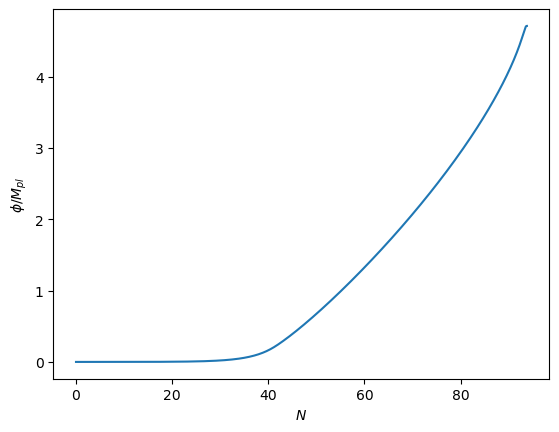

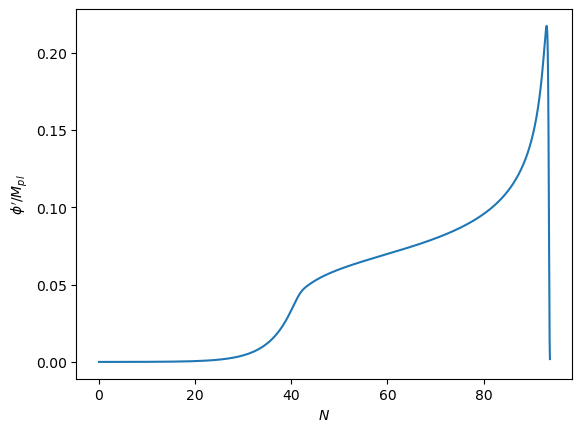

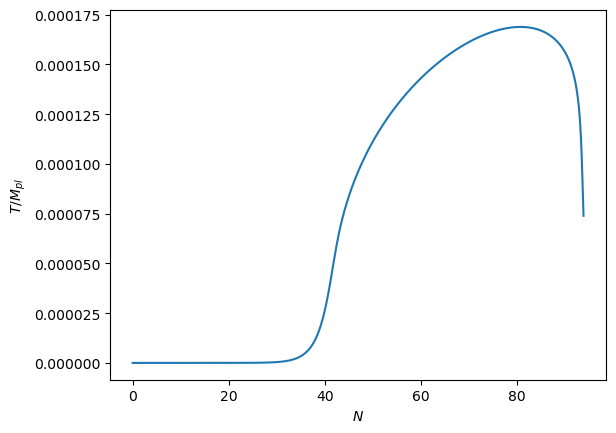

In [3]:
#Load and plot Bg files
if (write_bg == True):
    Narr, phi_arr, php_arr, T_arr = np.loadtxt(fname_bg,unpack=True,delimiter=",",skiprows=1)

    plt.plot(Narr,phi_arr)
    plt.ylabel(r"$\phi/M_{pl}$")
    plt.xlabel(r"$N$")
    plt.show()
    plt.plot(Narr,php_arr)
    plt.ylabel(r"$\phi'/M_{pl}$")
    plt.xlabel(r"$N$")
    plt.show()
    plt.plot(Narr,T_arr)
    plt.ylabel(r"$T/M_{pl}$")
    plt.xlabel(r"$N$")
    plt.show()
else:
    print("BG file was not generated. Check the parameter 'write_bg' in ps_script.py")

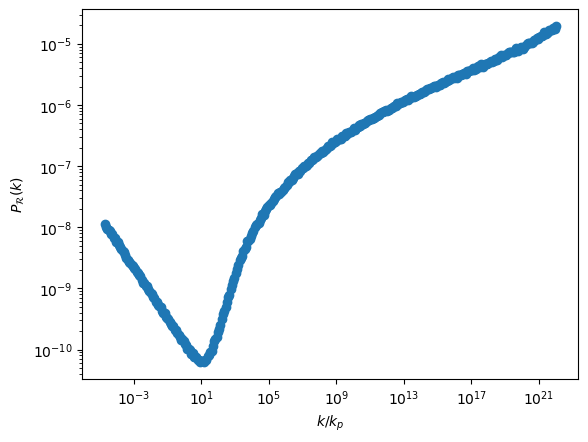

In [4]:
#Load and plot raw power spectrum files
karr,Parr = np.loadtxt(fname_ps,unpack=True,delimiter=",",skiprows=1)

plt.scatter(karr/kp,Parr)
plt.xscale("log")
plt.yscale("log")
plt.ylabel(r"$P_{\mathcal{R}}(k)$")
plt.xlabel(r"$k/k_p$")
plt.show()

In [5]:
#Smooth and fit the PS fitting function
popt,pcov = curve_fit(fitting_fn,np.log(karr),np.log(Parr))
print("As: ",np.exp(popt[0]))
print("ns: ",popt[1])
print("alpha_s: ",popt[2])
print("beta_s: ",popt[3])
PT = np.loadtxt("PT_kp.dat")
print("r: ",PT/np.exp(popt[0]))

As:  7.644567402896162e-10
ns:  1.0601647366432876
alpha_s:  0.026098155906816405
beta_s:  -0.0013006269660041751
r:  0.00037849178876487883


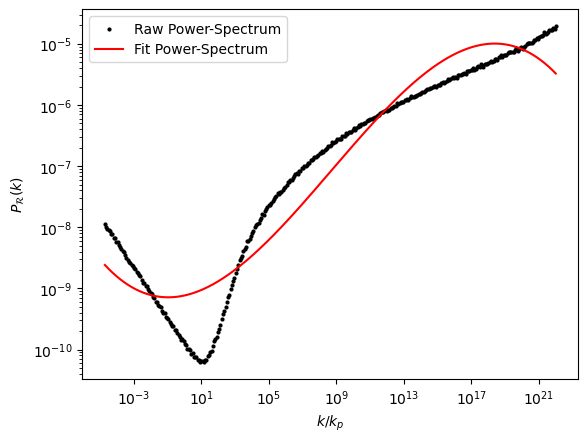

In [6]:
#Plot all the plots toget for comparison

plt.scatter(karr/kp,Parr,label="Raw Power-Spectrum",s=4,color='k')
# plt.plot(karr/kp,Parr_sm,label="Smoothed Power-Spectrum",linestyle="--",color="green")
plt.plot(karr/kp,np.exp(fitting_fn(np.log(karr),popt[0],popt[1],popt[2],popt[3])),label="Fit Power-Spectrum",color="red")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.xlabel(r"$k/k_p$")
plt.ylabel(r"$P_\mathcal{R}(k)$")
plt.show()

N_end: 92.9125
N_reh: 93.7962
N_pivot:  37.1629213134651


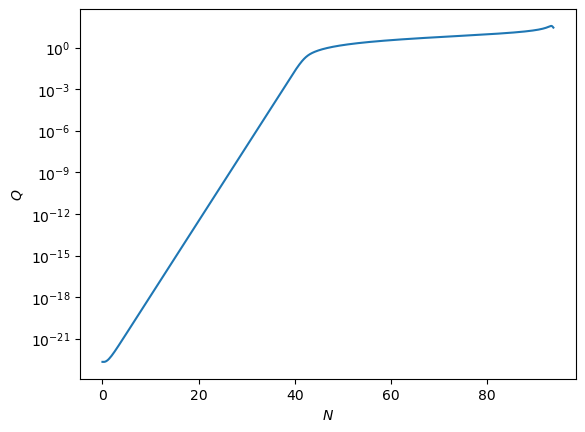

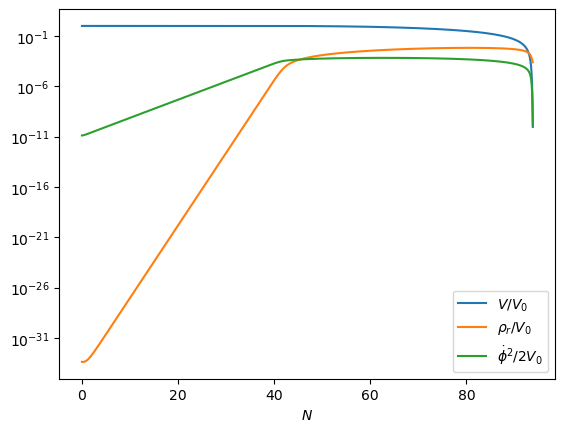

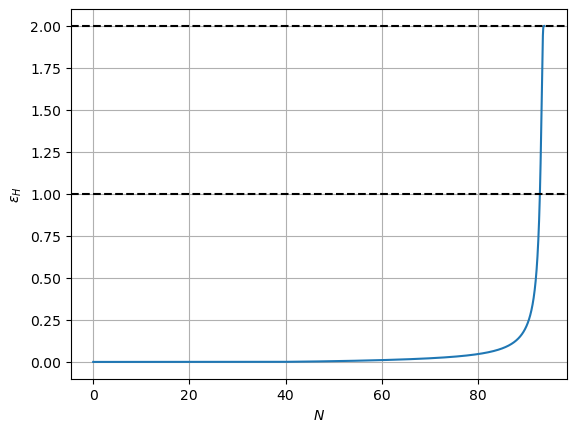

In [7]:
#Diagnostic plots for background
from scipy import optimize
from scipy.interpolate import CubicSpline
import functions_bg_diag as diag

Harr = diag.H(phi_arr, php_arr, T_arr)
Hparr = diag.Hp(phi_arr, php_arr, T_arr)
Qarr = diag.Q(phi_arr, php_arr, T_arr)
eHarr = diag.eH(phi_arr, php_arr, T_arr)

for i,j,k,l,m in zip(Narr,eHarr,T_arr,phi_arr,php_arr):
    if (j<=1.0):
        Nend = i
    elif ((j>1.0) and (j<=2.0)) or (diag.weff(l,m,k)<0.33):
        Nreh = i
        Treh = k

#required to calculate Npivot
if (Np_autocalc == 1):
    Narr_uniq, indx = np.unique(Narr, return_index=True)
    phiasN = CubicSpline(Narr_uniq, phi_arr[indx])
    phpasN = CubicSpline(Narr_uniq, php_arr[indx])
    TasN = CubicSpline(Narr_uniq, T_arr[indx])
    def ff(Ntry):
        Htry = diag.H(phiasN(Ntry),phpasN(Ntry),TasN(Ntry))
        return (kp*2.63e-57) - (np.exp(Ntry-Nreh)*( (43.0/(11.0*(106.75)))**(1.0/3.0) )*((2.349e-13*4.11e-19)/(Treh))*(Htry));
    Npivot = optimize.bisect(ff,0,Nend,maxiter=20000)
else:
    Npivot = Np

print("N_end:",Nend)
print("N_reh:",Nreh)
print("N_pivot: ",Npivot)

#Q plot
plt.plot(Narr,Qarr)
plt.yscale("log",base=10)
plt.ylabel("$Q$")
plt.xlabel("$N$")
plt.show()

#Energy densities plot
plt.plot(Narr,diag.V(phi_arr)/diag.V(phi_arr[0]),label=r"$V/V_0$")
plt.plot(Narr,(diag.Cr*T_arr**4)/diag.V(phi_arr[0]),label=r"$\rho_r/V_0$")
plt.plot(Narr,(((Harr*php_arr)**2)/2)/diag.V(phi_arr[0]),label=r"$\dot{\phi}^2/2V_0$")
plt.yscale("log",base=10)
plt.xlabel("$N$")
plt.legend()
plt.show()

#\epsilon_H plot
plt.plot(Narr,eHarr)
plt.axhline(1.0,linestyle="--",color="k")
plt.axhline(2.0,linestyle="--",color="k")
plt.xlabel("$N$")
plt.ylabel(r"$\epsilon_H$")
plt.grid()
plt.show()